<a href="https://colab.research.google.com/github/sastha-06/24ADI006_DL_24BAD106/blob/main/24BAD106_DL_EX6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PART A**

In [2]:
# PART A: DATASET PREPARATION AND TEXT PREPROCESSING

print("Name: Sastha Jeyasri A.")
print("Roll No: 24BAD106")
print("PART A: DATASET PREPARATION AND TEXT PREPROCESSING")

# Download IMDB dataset
!wget -q https://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz

# Extract the dataset
!tar -xzf aclImdb_v1.tar.gz

print("\nIMDB dataset downloaded and extracted successfully.")

Name: Sastha Jeyasri A.
Roll No: 24BAD106
PART A: DATASET PREPARATION AND TEXT PREPROCESSING

IMDB dataset downloaded and extracted successfully.


In [23]:
import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding,Input
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import LSTM, Dense,Dropout

print("Required libraries imported successfully.")

Required libraries imported successfully.


In [4]:
print("Name: Sastha Jeyasri A.")
print("Roll No: 24BAD106")
def load_reviews(folder_path):
    reviews = []
    labels = []
    # Positive reviews
    positive_path = os.path.join(folder_path, "pos")

    for filename in os.listdir(positive_path):
        if filename.endswith(".txt"):
            file_path = os.path.join(positive_path, filename)

            with open(file_path, "r", encoding="utf-8") as file:
                reviews.append(file.read())

            labels.append(1)
    # Negative reviews
    negative_path = os.path.join(folder_path, "neg")
    for filename in os.listdir(negative_path):
        if filename.endswith(".txt"):
            file_path = os.path.join(negative_path, filename)

            with open(file_path, "r", encoding="utf-8") as file:
                reviews.append(file.read())

            labels.append(0)

    return reviews, labels
train_reviews, train_labels = load_reviews("/content/aclImdb/train")
test_reviews, test_labels = load_reviews("/content/aclImdb/test")

print("Training reviews:", len(train_reviews))
print("Testing reviews:", len(test_reviews))

Name: Sastha Jeyasri A.
Roll No: 24BAD106
Training reviews: 25000
Testing reviews: 25000


In [5]:
train_df = pd.DataFrame({
    "review": train_reviews,
    "sentiment": train_labels
})

test_df = pd.DataFrame({
    "review": test_reviews,
    "sentiment": test_labels
})

print("Training Dataset:")
display(train_df.head())

print("\nTesting Dataset:")
display(test_df.head())

Training Dataset:


,review,sentiment
0,Will Smith delivers yet again in a film about ...,1
1,Christopher Lloyd is funny and really believab...,1
2,I finally saw this film tonight after renting ...,1
3,The Stock Market Crash of 1929 and the Depress...,1
4,And I'll tell you why: whoever decided to edit...,1



Testing Dataset:


,review,sentiment
0,This is a profound and moving work about the c...,1
1,This is without doubt the most exciting and sa...,1
2,This is one of the best movies I've seen. The ...,1
3,This short movie intends to focus on one issue...,1
4,"I just bought this movie yesterday night, and ...",1


In [6]:
print("Name: Sastha Jeyasri A.")
print("Roll No: 24BAD106")

print("----- SAMPLE POSITIVE REVIEW -----")
print(train_df[train_df["sentiment"] == 1]["review"].iloc[0])

print("\n----- SAMPLE NEGATIVE REVIEW -----")
print(train_df[train_df["sentiment"] == 0]["review"].iloc[0])

Name: Sastha Jeyasri A.
Roll No: 24BAD106
----- SAMPLE POSITIVE REVIEW -----
Will Smith delivers yet again in a film about a man with the weight of the world on his shoulders and his crusade to right his wrongs in a way that will touch even the most hardened of hearts!!! Writer Grant Nieporte and Italian Director Gabriele Muccino come together and created a masterpiece that I highly recommend to purchase and keep in your movie collection as you will never grow tired of watching/feeling this film!!! I have the Highest Respects for Will Smith as he is not only a brilliant Actor but one can tell he has a genuine love for people and life which no doubt made him perfect for the character (IRS Agent Ben Thomas) he played in this film. You will find yourself feeling his pain and anger, the frustrations over his love for Emily, played by Rosario Dawson, who by the way was Fantastic as usual. I found myself falling in love with the fact their characters were falling in love. Woody Harrelson als

In [7]:
print("Sentiment Class Distribution")

print("\nTraining Dataset:")
print(train_df["sentiment"].value_counts())

print("\n0 = Negative")
print("1 = Positive")

Sentiment Class Distribution

Training Dataset:
sentiment
1    12500
0    12500
Name: count, dtype: int64

0 = Negative
1 = Positive


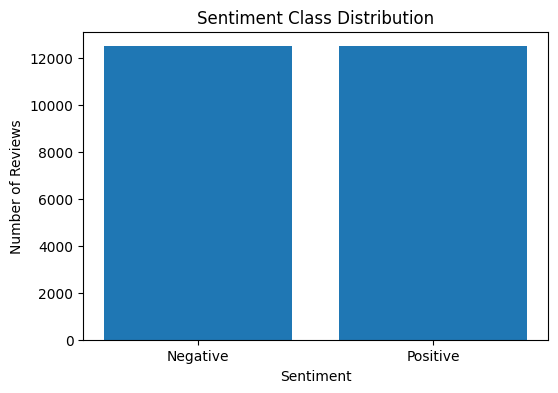

In [8]:
class_counts = train_df["sentiment"].value_counts().sort_index()

plt.figure(figsize=(6, 4))

plt.bar(["Negative", "Positive"], class_counts.values)

plt.title("Sentiment Class Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")

plt.show()

In [9]:
def clean_text(text):
    # Convert to lowercase
    text = text.lower()

    # Remove HTML tags
    text = re.sub(r"<br\s*/?>", " ", text)

    # Remove punctuation and special characters
    text = re.sub(r"[^a-zA-Z\s]", "", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


train_df["clean_review"] = train_df["review"].apply(clean_text)
test_df["clean_review"] = test_df["review"].apply(clean_text)

print("Text preprocessing completed.")

print("\nOriginal Review:")
print(train_df["review"].iloc[0][:500])

print("\nCleaned Review:")
print(train_df["clean_review"].iloc[0][:500])

Text preprocessing completed.

Original Review:
Will Smith delivers yet again in a film about a man with the weight of the world on his shoulders and his crusade to right his wrongs in a way that will touch even the most hardened of hearts!!! Writer Grant Nieporte and Italian Director Gabriele Muccino come together and created a masterpiece that I highly recommend to purchase and keep in your movie collection as you will never grow tired of watching/feeling this film!!! I have the Highest Respects for Will Smith as he is not only a brilliant 

Cleaned Review:
will smith delivers yet again in a film about a man with the weight of the world on his shoulders and his crusade to right his wrongs in a way that will touch even the most hardened of hearts writer grant nieporte and italian director gabriele muccino come together and created a masterpiece that i highly recommend to purchase and keep in your movie collection as you will never grow tired of watchingfeeling this film i have the hig

In [10]:
print("Name: Sastha Jeyasri A.")
print("Roll No: 24BAD106")

# Maximum vocabulary size
vocab_size = 10000

# Create tokenizer
tokenizer = Tokenizer(num_words=vocab_size, oov_token="<OOV>")

# Build vocabulary using training reviews
tokenizer.fit_on_texts(train_df["clean_review"])

print("Vocabulary created successfully.")
print("Vocabulary size:", len(tokenizer.word_index))

Name: Sastha Jeyasri A.
Roll No: 24BAD106
Vocabulary created successfully.
Vocabulary size: 108662


In [11]:
train_sequences = tokenizer.texts_to_sequences(train_df["clean_review"])
test_sequences = tokenizer.texts_to_sequences(test_df["clean_review"])

print("Text converted into numerical sequences.")

print("\nSample Original Text:")
print(train_df["clean_review"].iloc[0][:200])

print("\nSample Numerical Sequence:")
print(train_sequences[0][:30])

Text converted into numerical sequences.

Sample Original Text:
will smith delivers yet again in a film about a man with the weight of the world on his shoulders and his crusade to right his wrongs in a way that will touch even the most hardened of hearts writer g

Sample Numerical Sequence:
[76, 1235, 1477, 241, 172, 8, 4, 19, 42, 4, 133, 16, 2, 3324, 5, 2, 185, 20, 24, 5105, 3, 24, 1, 6, 203, 24, 1, 8, 4, 94]


In [12]:
max_length = 200

X_train = pad_sequences(
    train_sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_test = pad_sequences(
    test_sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

y_train = np.array(train_labels)
y_test = np.array(test_labels)

print("Sequence padding completed.")

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Sequence padding completed.
Training data shape: (25000, 200)
Testing data shape: (25000, 200)


In [13]:
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Dataset split completed.")

print("Training samples:", X_train.shape[0])
print("Validation samples:", X_val.shape[0])
print("Testing samples:", X_test.shape[0])

Dataset split completed.
Training samples: 20000
Validation samples: 5000
Testing samples: 25000


In [14]:
print("Name: Sastha Jeyasri A.")
print("Roll No: 24BAD106")
print("Training samples:", X_train.shape[0])
print("Validation samples:", X_val.shape[0])
print("Testing samples:", X_test.shape[0])
print("Vocabulary size:", vocab_size)
print("Maximum sequence length:", max_length)

Name: Sastha Jeyasri A.
Roll No: 24BAD106
Training samples: 20000
Validation samples: 5000
Testing samples: 25000
Vocabulary size: 10000
Maximum sequence length: 200


# **PART B**

In [15]:
print("Name: Sastha Jeyasri A.")
print("Roll No: 24BAD106")
print("PART B: EMBEDDING GENERATION")

# Vocabulary size
vocab_size = 10000

# Embedding dimension
embedding_dim = 100

# Maximum sequence length
max_length = 200

print("Vocabulary Size:", vocab_size)
print("Embedding Dimension:", embedding_dim)
print("Maximum Sequence Length:", max_length)

Name: Sastha Jeyasri A.
Roll No: 24BAD106
PART B: EMBEDDING GENERATION
Vocabulary Size: 10000
Embedding Dimension: 100
Maximum Sequence Length: 200


In [16]:
embedding_layer = Embedding(
    input_dim=vocab_size,
    output_dim=embedding_dim,
    input_length=max_length
)

print("Embedding layer created successfully.")

Embedding layer created successfully.


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [17]:
# Take the first 5 padded reviews
sample_sequences = X_train[:5]

# Generate embeddings
embedded_output = embedding_layer(sample_sequences)

print("Name: Sastha Jeyasri A.")
print("Roll No: 24BAD106")

print("\nEmbedding representation generated.")
print("Input shape:", sample_sequences.shape)
print("Embedding output shape:", embedded_output.shape)

Name: Sastha Jeyasri A.
Roll No: 24BAD106

Embedding representation generated.
Input shape: (5, 200)
Embedding output shape: (5, 200, 100)


In [18]:
# Get the word index for a sample word
word = "good"

if word in tokenizer.word_index:
    word_index = tokenizer.word_index[word]

    if word_index < vocab_size:
        word_vector = embedding_layer(
            tf.constant([[word_index]])
        )

        print("Name: Sastha Jeyasri A.")
        print("Roll No: 24BAD106")
        print("\nWord:", word)
        print("Word Index:", word_index)
        print("Embedding Vector:")
        print(word_vector.numpy()[0][0])
    else:
        print("Word is outside the selected vocabulary.")
else:
    print("Word not found in vocabulary.")

Name: Sastha Jeyasri A.
Roll No: 24BAD106

Word: good
Word Index: 49
Embedding Vector:
[-0.00920802  0.04913421 -0.03897766  0.03021744  0.0459537  -0.01183268
 -0.02447512  0.03309306 -0.03120695  0.02841837 -0.0467103   0.00278413
  0.04206785  0.0375258   0.01069673  0.04736844 -0.03119132 -0.04092373
  0.03777487  0.02412682 -0.04226874 -0.00112609 -0.03779256 -0.01430999
  0.01073205  0.00193839  0.04405502 -0.0221482  -0.02473219 -0.00546991
 -0.03407653 -0.02646091  0.02419709  0.01664957  0.02218335 -0.00668368
  0.020364   -0.0063488  -0.02069722 -0.03112145  0.04741708 -0.04660235
  0.01705613 -0.00330646 -0.04334005 -0.0309881  -0.02622088 -0.00614352
 -0.00230011 -0.01607154  0.04438588  0.04486408 -0.04421365 -0.00912265
 -0.02712841 -0.00116998  0.01413736 -0.04258354 -0.03853049  0.0331152
 -0.04989983 -0.02880212 -0.03315346  0.03400541  0.00684208 -0.00279337
 -0.00428665  0.04616909 -0.03311316 -0.03083109 -0.025606   -0.00144074
  0.03737267  0.04241475 -0.00190618  

In [19]:
print("Name: Sastha Jeyasri A.")
print("Roll No: 24BAD106")

print("Vocabulary Size:", vocab_size)
print("Embedding Dimension:", embedding_dim)
print("Input Shape:", sample_sequences.shape)
print("Embedding Output Shape:", embedded_output.shape)

Name: Sastha Jeyasri A.
Roll No: 24BAD106
Vocabulary Size: 10000
Embedding Dimension: 100
Input Shape: (5, 200)
Embedding Output Shape: (5, 200, 100)


# **PART C**

In [20]:
print("Name: Sastha Jeyasri A.")
print("Roll No: 24BAD106")
vocab_size = 10000
embedding_dim = 100
max_length = 200

print("Vocabulary Size:", vocab_size)
print("Embedding Dimension:", embedding_dim)
print("Maximum Sequence Length:", max_length)

Name: Sastha Jeyasri A.
Roll No: 24BAD106
Vocabulary Size: 10000
Embedding Dimension: 100
Maximum Sequence Length: 200


In [24]:
print("Name: Sastha Jeyasri A.")
print("Roll No: 24BAD106")
model = Sequential([
    Input(shape=(max_length,)),
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
    ),
    LSTM(64,dropout=0.2,recurrent_dropout=0.2),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])
print("LSTM model created successfully.")
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)
print("Model compiled successfully.")
model.summary()

Name: Sastha Jeyasri A.
Roll No: 24BAD106
LSTM model created successfully.
Model compiled successfully.


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 200, 100)       │     1,000,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        42,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,042,305 (3.98 MB)

 Trainable params: 1,042,305 (3.98 MB)

 Non-trainable params: 0 (0.00 B)

# **`PART D`**

In [25]:
# PART D: MODEL TRAINING AND SENTIMENT PREDICTION
print("Name: Sastha Jeyasri A.")
print("Roll No: 24BAD106")
print("PART D: MODEL TRAINING AND SENTIMENT PREDICTION")
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=64,
    validation_data=(X_val, y_val),
    verbose=1
)
print("\nTraining Accuracy:")
print(history.history["accuracy"])
print("\nValidation Accuracy:")
print(history.history["val_accuracy"])
print("\nTraining Loss:")
print(history.history["loss"])
print("\nValidation Loss:")
print(history.history["val_loss"])

Name: Sastha Jeyasri A.
Roll No: 24BAD106
PART D: MODEL TRAINING AND SENTIMENT PREDICTION
Epoch 1/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 109s 333ms/step - accuracy: 0.5312 - loss: 0.6902 - val_accuracy: 0.5144 - val_loss: 0.6913
Epoch 2/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 103s 330ms/step - accuracy: 0.6053 - loss: 0.6622 - val_accuracy: 0.6524 - val_loss: 0.6390
Epoch 3/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 133s 303ms/step - accuracy: 0.6474 - loss: 0.6139 - val_accuracy: 0.5934 - val_loss: 0.6327
Epoch 4/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 142s 305ms/step - accuracy: 0.7194 - loss: 0.5428 - val_accuracy: 0.7608 - val_loss: 0.5460
Epoch 5/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 141s 301ms/step - accuracy: 0.6162 - loss: 0.6386 - val_accuracy: 0.5934 - val_loss: 0.6504
Epoch 6/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 94s 300ms/step - accuracy: 0.7539 - loss: 0.5043 - val_accuracy: 0.7818 - val_loss: 0.5184
Epoch 7/10
313/313 ━━━━━━━━━━━━━━━━━━━━ 143s 304ms/step - accuracy: 0.8553 - loss: 0.3715 - val_accuracy: 0.8282 - val_

Name: Sastha Jeyasri A.
Roll No: 24BAD106


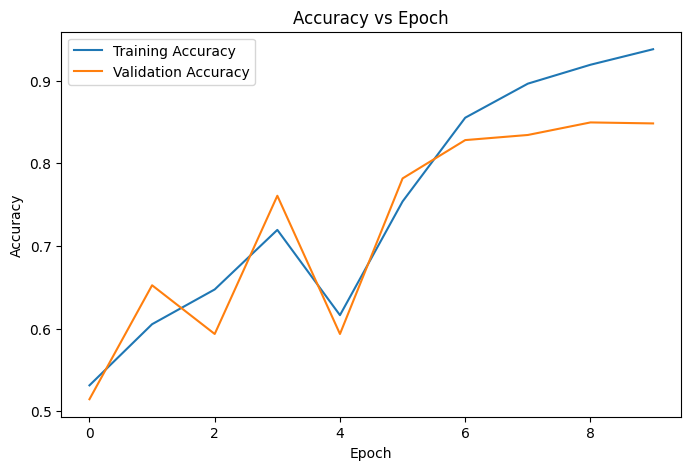

In [26]:
print("Name: Sastha Jeyasri A.")
print("Roll No: 24BAD106")
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Accuracy vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

Name: Sastha Jeyasri A.
Roll No: 24BAD106


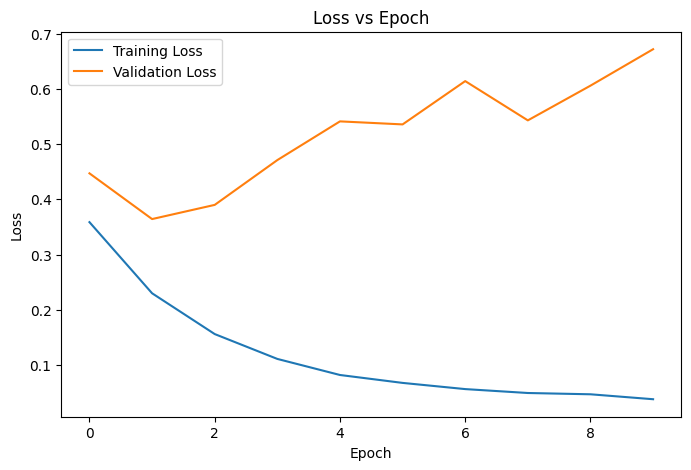

In [35]:
print("Name: Sastha Jeyasri A.")
print("Roll No: 24BAD106")
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [27]:
test_loss, test_accuracy = model.evaluate(
    X_test,
    y_test,
    verbose=1
)
print("\nName: Sastha Jeyasri A.")
print("Roll No: 24BAD106")
print("\nTest Loss:", test_loss)
print("Test Accuracy:", test_accuracy)
y_probability = model.predict(X_test)
# Convert probability into 0 or 1
y_pred = (y_probability >= 0.5).astype(int).flatten()
print("Predictions generated successfully.")
print("\nFirst 10 predicted values:")
print(y_pred[:10])
print("\nFirst 10 actual values:")
print(y_test[:10])
sample_reviews = [
    "This movie was amazing and I really enjoyed watching it.",
    "The movie was boring and disappointing.",
    "Excellent acting and a wonderful story.",
    "I hated this movie. It was a complete waste of time."
]
# Clean the sample reviews
clean_samples = [clean_text(review) for review in sample_reviews]
# Convert to sequences
sample_sequences = tokenizer.texts_to_sequences(clean_samples)
# Apply padding
sample_padded = pad_sequences(
    sample_sequences,
    maxlen=max_length,
    padding="post",
    truncating="post"
)
# Predict
sample_predictions = model.predict(sample_padded)
print("Name: Sastha Jeyasri A.")
print("Roll No: 24BAD106")
print("\nSample Sentiment Predictions:")
for review, prediction in zip(sample_reviews, sample_predictions):
    if prediction[0] >= 0.5:
        sentiment = "Positive"
    else:
        sentiment = "Negative"

    print("\nReview:", review)
    print("Prediction:", sentiment)
    print("Probability:", float(prediction[0]))

782/782 ━━━━━━━━━━━━━━━━━━━━ 31s 40ms/step - accuracy: 0.8266 - loss: 0.5035

Name: Sastha Jeyasri A.
Roll No: 24BAD106

Test Loss: 0.5035451054573059
Test Accuracy: 0.8266400098800659
782/782 ━━━━━━━━━━━━━━━━━━━━ 33s 42ms/step
Predictions generated successfully.

First 10 predicted values:
[1 1 1 0 1 1 1 1 0 1]

First 10 actual values:
[1 1 1 1 1 1 1 1 1 1]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step
Name: Sastha Jeyasri A.
Roll No: 24BAD106

Sample Sentiment Predictions:

Review: This movie was amazing and I really enjoyed watching it.
Prediction: Positive
Probability: 0.9770842790603638

Review: The movie was boring and disappointing.
Prediction: Negative
Probability: 0.02843785658478737

Review: Excellent acting and a wonderful story.
Prediction: Positive
Probability: 0.979307234287262

Review: I hated this movie. It was a complete waste of time.
Prediction: Negative
Probability: 0.028119416907429695


In [28]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Name: Sastha Jeyasri A.")
print("Roll No: 24BAD106")

print("\nEvaluation Metrics")
print("-------------------------")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-Score :", f1)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

Name: Sastha Jeyasri A.
Roll No: 24BAD106

Evaluation Metrics
-------------------------
Accuracy : 0.82664
Precision: 0.8518614270941055
Recall   : 0.7908
F1-Score : 0.8201958181214736

Confusion Matrix:
[[10781  1719]
 [ 2615  9885]]


Name: Sastha Jeyasri A.
Roll No: 24BAD106


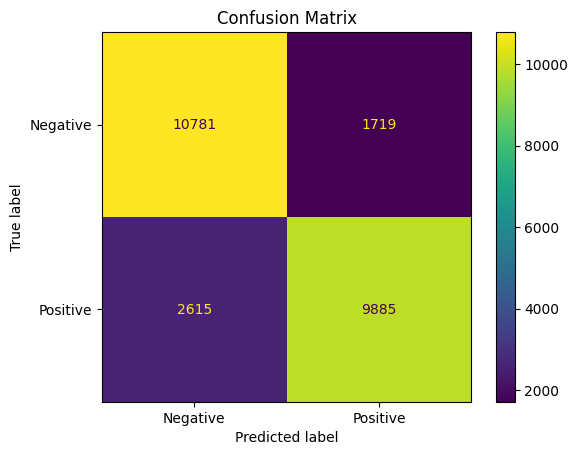

In [29]:
print("Name: Sastha Jeyasri A.")
print("Roll No: 24BAD106")
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Negative", "Positive"]
)

disp.plot()

plt.title("Confusion Matrix")
plt.show()